# 阶段 1 结果：记忆的 token 应该写在哪里
**配套文档：** [讨论稿](../../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 21 节（实验规格，跑之前写定）· [pipeline.ipynb](pipeline.ipynb)（各环节的想法）· [pipeline_examples.ipynb](pipeline_examples.ipynb)（每个环节的一个示例）· SceneFun3D 验证集的 30 个场景 · 2026-11-12

**这次实验回答的问题（预测 A）：** 记忆的预算相同时，由 affordance 决定位置的 token，是否比按其他方式取的 token 更常把正确的证据检索出来。

**读之前请注意**

- **affordance map 是 ORACLE**（标注投影得到，不带部件编号）。所以这里所有数字都是**上限**：它们说明"如果 affordance map 是对的，按它来写记忆值不值得"，不说明现在的模型能做到多少。换成模型预测的 affordance map 是阶段 2 的事。
- **没有训练任何东西。** 图文编码器（SigLIP 2）、通用分割模型（SAM）、视觉语言模型（Qwen3-VL-4B）、单目深度模型（Depth Anything V2）都是现成的公开模型。
- **判定标准在跑实验之前写定**（讨论稿第 21.6 节），本文第 10 节按原样套用，没有因为结果而修改。
- **图里的英文标签：** P0 whole keyframes = 只有整帧；P1 uniform grid = 均匀网格；P2 random places = 随机位置；P3 generic regions = 通用区域；P4 affordance regions = affordance 区域。每种写法在所有图里用同一种颜色。

<sub>重新运行：`python scripts/download_scenefun3d_keyframes.py` 取 30 个场景的关键帧；`bash scripts/remote/queue_phase1.sh` 把每个场景的作业放进 GPU 队列（结果写到 `runs/mem_phase1/`）；`python scripts/aggregate_mem_phase1.py` 汇总；然后 Run All（CPU，几分钟，第 3 节和第 8 节会在一个场景上重新算一遍检索）。</sub>

In [1]:
import contextlib
import io
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")  # no model-loading chatter in the outputs
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.mem import keyframes as K
from affordance3d.mem import phase1_stats as A
from affordance3d.mem import pipeline as P
from affordance3d.mem import search as S
from affordance3d.mem import tokens as T
from affordance3d.mem.encoders import ImageTextEncoder
from report import mem_phase1_helpers as R
from report import mem_steps_helpers as H
from report.mem_demo_helpers import scaled_mono_depths

from transformers.utils import logging as transformers_logging

transformers_logging.disable_progress_bar()
plt.rcParams.update({"figure.dpi": 100})
pd.set_option("display.max_colwidth", 120)
torch.set_num_threads(48)  # shared server: leave most cores to others
DATA, RUNS = ROOT / "data" / "scenefun3d", ROOT / "runs" / "mem_phase1"
MONO_ID = "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf"
results, summary = R.load_runs(RUNS)  # written by scripts/run_mem_phase1.py and scripts/aggregate_mem_phase1.py
diagnostics = R.load_diagnostics(RUNS)  # the follow-up check of section 11, written by scripts/diagnose_mem_phase1.py
print(f"{summary['scenes']} scenes, {summary['tasks']} answerable tasks")

30 scenes, 390 answerable tasks


## 1. 比较的是什么

**记忆的形式（L2）：** 每个关键帧存一张图，再加若干个 token。一个 token 对应关键帧里的一个小区域，存的是这个区域周围一块画面的图文特征。查询来了以后，用查询句子的特征去和整帧、和 token 分别比较，两个分数相加，给关键帧排序。

**这次只改变一件事：token 取在哪里。** 编码器、裁剪规则、打分公式、查询句子全部相同。

| 编号 | 写法 | token 取在哪里 |
| --- | --- | --- |
| P0 | 只有整帧 | 没有 token。没有 affordance 的记忆只能这样检索 |
| P1 | 均匀网格 | 每个关键帧切成固定的格子，每格一个 token |
| P2 | 随机位置 | 个数和大小与 P4 相同，位置随机。只改变"在哪里" |
| P3 | 通用区域 | 不知道 affordance 的分割模型（SAM）给出的区域，按大小与 P4 匹配后随机取 |
| P4 | affordance 区域 | affordance map（ORACLE）上的每一个连通区域 |

- **预算：** 以一个场景里 P4 的 token 数为 1 倍。主要比较在 1 倍上做，另外在 0.25 到 8 倍之间画曲线。
- **主要指标：** 排在第 1 位的关键帧里有没有任务所指的部件（下面叫"第一个关键帧对"），以及前 3 位里有没有。这个指标不依赖 token 的形状，对各种写法公平。
- **统计：** 同一个场景的任务共用一份记忆，所以按场景做自助抽样，给出 95% 置信区间；两种写法的差在同一批任务上成对比较。P2、P3 各用 5 个随机种子，取平均。

## 2. 数据

- **场景：** SceneFun3D 的 30 个验证场景（Fun3DU 和 UniFunc3D 用的 split0），每个场景用文件清单指定的一段视频。
- **关键帧：** 每段视频 40 帧。把视频按时间分成 40 段，每段取设备位姿转得最慢的一帧（只用输入）。
- **"可回答"的任务：** 任务所指的部件至少在一个关键帧里占 10 个像素。看不到的部件，任何写法都检索不到，所以主要数字只在可回答的任务上统计。

第二张表是关键帧处相机转动的快慢（由设备位姿算出）。相机转得快的帧里，标注和画面会错位，所以选转得慢的帧；"均匀取帧"一行是对照。

In [2]:
display(R.data_table(results, summary))
no_lidar = summary.get("keyframes_without_lidar", {})
print("keyframes whose LiDAR frame has no reliable pixel (depth scale taken from the other keyframes of the scene):",
      {visit: len(frames) for visit, frames in no_lidar.items()} or "none")
display(R.turn_rate_table(DATA, results))

,value
what,
scenes scored,30
scenes without an answerable task (not scored),0
tasks: all / answerable (the part is visible in a keyframe),445 / 390
keyframes per scene,40
annotated parts (all scenes run),561
"of these, visible in the steady keyframes / in evenly spaced keyframes",481 / 501
P4 tokens per scene: median (smallest to largest),63 (10 to 115)
generic regions per scene (pool of P3): median,2265


keyframes whose LiDAR frame has no reliable pixel (depth scale taken from the other keyframes of the scene): {'422842': 1, '423070': 1, '434888': 2, '438775': 1, '466112': 1, '466876': 1}


,keyframes,median turn rate (deg/s),90th percentile (deg/s),fastest (deg/s)
steady keyframes (used),1200.0,8.1,20.7,63.7
evenly spaced keyframes (for comparison),1200.0,21.0,42.0,116.2


## 3. 五种写法在画面上的样子

下面用一个场景的三个关键帧，画出预算为 1 倍时每种写法的 token 落在哪里。**这个场景不是挑出来的**：取的是"P4 与 P3 的差"在所有场景里居中的那一个（至少有 10 条可回答的任务）。

**怎么看图：** 每一行是同一个关键帧，每一列是一种写法，每个框是一个 token。三行分别是 affordance 区域最多、居中、最少的关键帧。P4 把 token 集中在有可操作部件的画面上；P1 平均铺开；P2、P3 的 token 总数与 P4 相同，但分散在所有关键帧里。

scene 468476: 51 affordance regions in 40 keyframes
keyframes without any token: {'P2 random places': 10, 'P3 generic regions': 15, 'P4 affordance regions': 17}


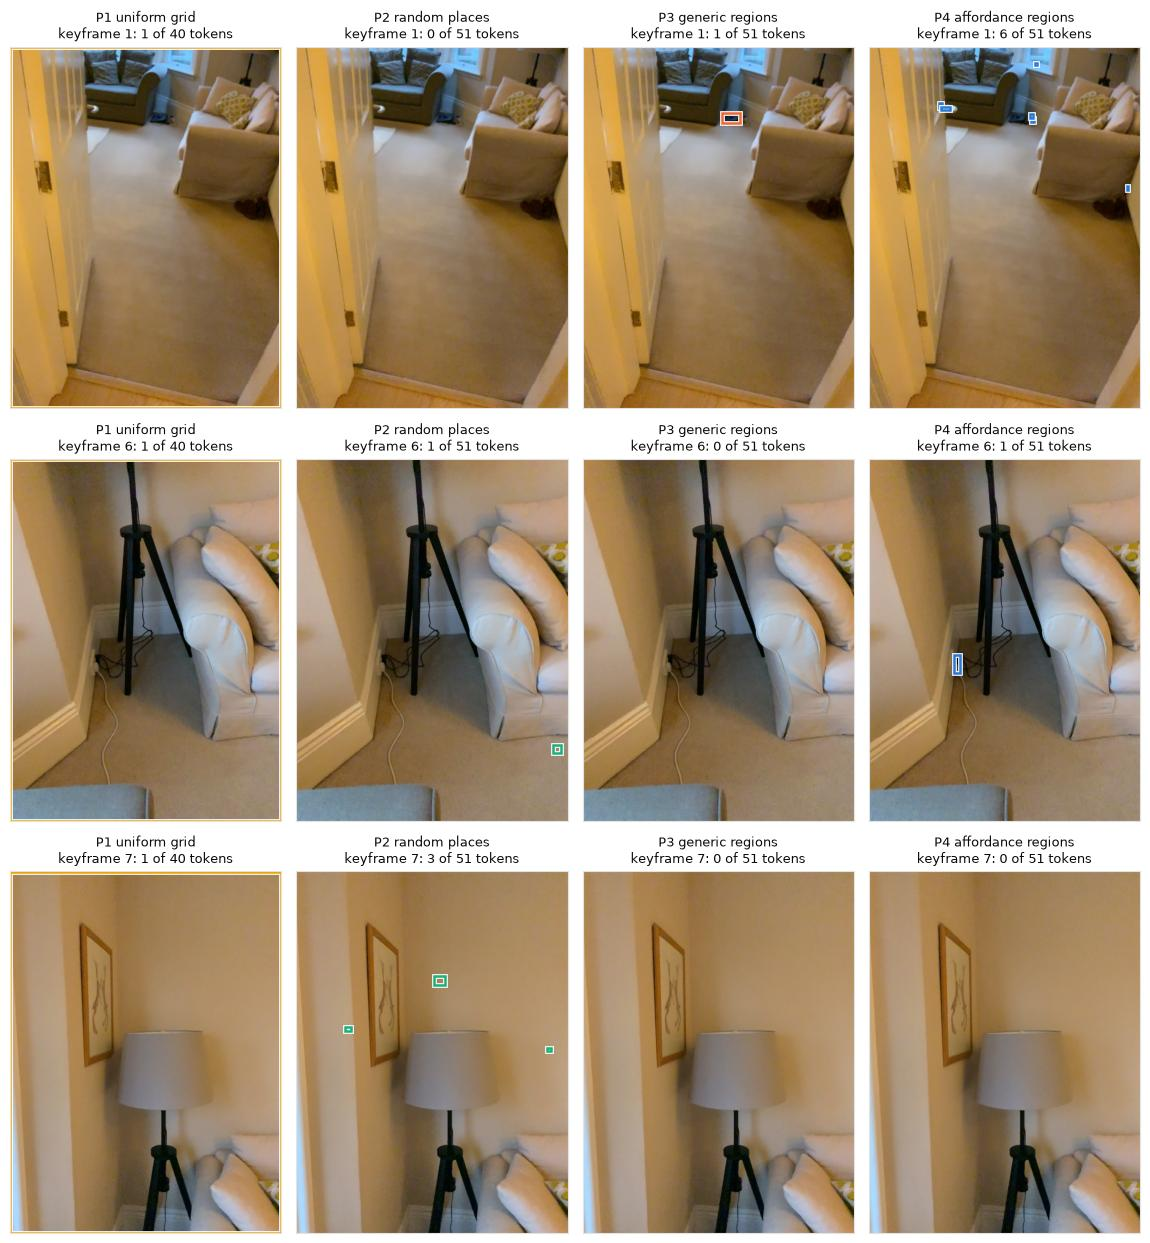

In [3]:
EXAMPLE = R.typical_scene(results)
example = next(result for result in results if result["visit"] == EXAMPLE)
scene = P.load_scene(DATA, EXAMPLE, example["video"])
times = K.scene_keyframes(scene, example["keyframes"], example["n_keyframes"])
mono = scaled_mono_depths(scene, times, MONO_ID, RUNS / "mono" / example["video"])  # cached by the GPU run
frames = [P.input_frame(scene, t, d) for t, d in zip(times, mono)]
labels = P.label_maps(scene, P.gt_frames(scene, times))  # ORACLE with part ids: scoring and drawing only
actions = [T.ACTIONS.index(e.label) if e.label in T.ACTIONS else T.NO_ACTION for e in scene.elements]
action_maps = [T.action_map(label, actions) for label in labels]  # the ORACLE affordance map: action types, no part ids
pool = R.generic_pool(RUNS / "regions" / f"{EXAMPLE}.json", frames[0].image_hw)
sets = R.token_sets(frames, action_maps, pool)  # the same random draws as the GPU run (seed 0)

per_keyframe = np.bincount([c.keyframe for c in sets[A.P4]], minlength=len(frames))
by_count = np.argsort(per_keyframe, kind="stable")
shown = [int(by_count[-1]), int(by_count[len(by_count) // 2]), int(by_count[0])]
empty = {R.POLICY_NAMES[name]: len(frames) - len({c.keyframe for c in sets[name]}) for name in (A.P2, A.P3, A.P4)}
print(f"scene {EXAMPLE}: {len(sets[A.P4])} affordance regions in {len(frames)} keyframes")
print("keyframes without any token:", empty)
set_matplotlib_formats("jpeg")
R.policies_figure(frames, sets, shown)
plt.show()

## 4. 主要结果：预算为 1 倍时

**怎么看图：** 左边是每种写法"第一个关键帧对"的比例，黑线是 95% 置信区间。右边是 P4 减去其他写法的差（同一批任务成对比较），横线是差值的 95% 置信区间；**区间不跨过 0，才算有差别**。

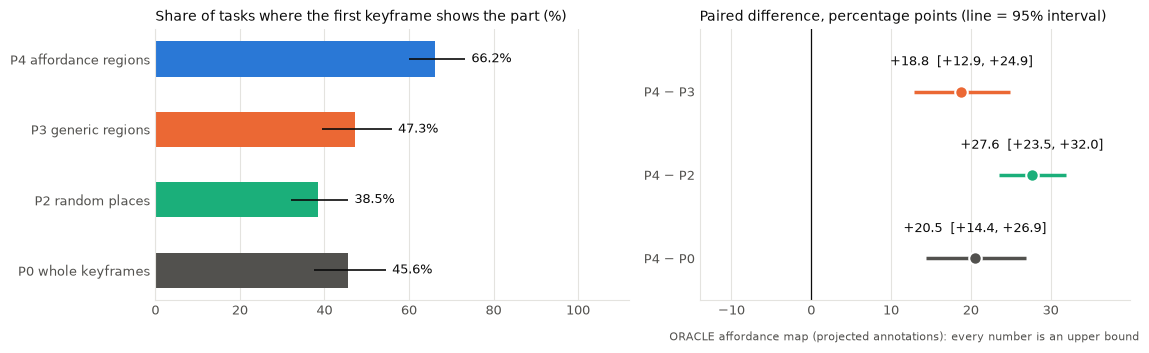

,value,"95% interval, low","95% interval, high"
P0,45.6,37.4,54.5
P2,38.5,32.0,45.6
P3,47.3,39.5,55.9
P4,66.2,60.0,73.3
P4 minus P0,20.5,14.4,26.9
P4 minus P2,27.6,23.5,32.0
P4 minus P3,18.8,12.9,24.9


In [4]:
set_matplotlib_formats("png")
R.headline_figure(summary, "first_keyframe_right", "the first keyframe shows the part")
plt.show()
display(R.rates_table(summary["first_keyframe_right"]))

同样的比较，换成"前 3 个关键帧里有没有"（之后交给视觉语言模型看的就是前 3 个关键帧）：

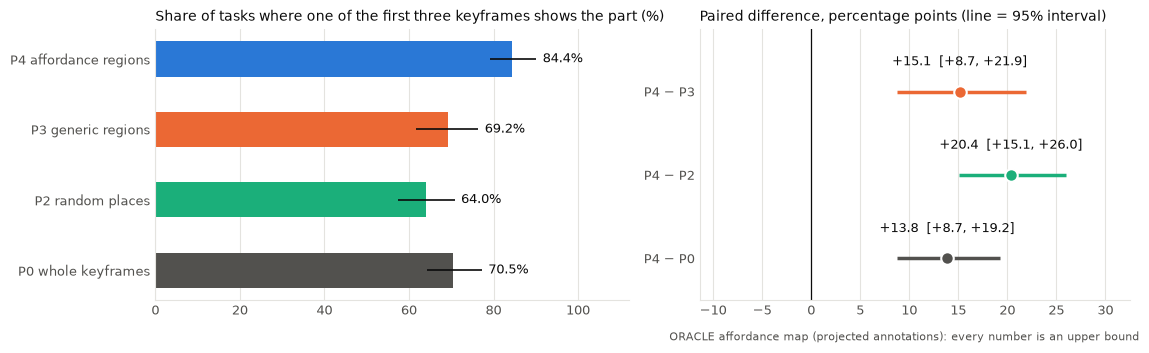

,value,"95% interval, low","95% interval, high"
P0,70.5,64.3,77.3
P2,64.0,57.3,70.8
P3,69.2,61.8,76.4
P4,84.4,79.1,90.1
P4 minus P0,13.8,8.7,19.2
P4 minus P2,20.4,15.1,26.0
P4 minus P3,15.1,8.7,21.9


In [5]:
R.headline_figure(summary, "right_keyframe_in_top3", "one of the first three keyframes shows the part")
plt.show()
display(R.rates_table(summary["right_keyframe_in_top3"]))

## 5. 预算曲线：多给 token 能不能追上

**怎么看图：** 横轴是记忆的预算（token 数相对于 P4 的倍数，对数刻度），纵轴是"第一个关键帧对"的比例，色带是 95% 置信区间。虚线是只有整帧（P0）的水平。点线是第 11 节加的一组：不写任何 token，只告诉检索哪些关键帧里有 affordance 区域（每帧一个比特）。**这条点线不低于图上任何一种不按 affordance 写的方法（图上只画了 30 个场景都跑了的设置），所以曲线之间的差距不能读成 token 的效率**，第 11 节把帧级信息和 token 分开。P4 最多只有 1 倍（affordance 区域就这么多），其他写法一直给到 8 倍。P1 的格子数是固定的几档，所以它的点不落在整数倍上。

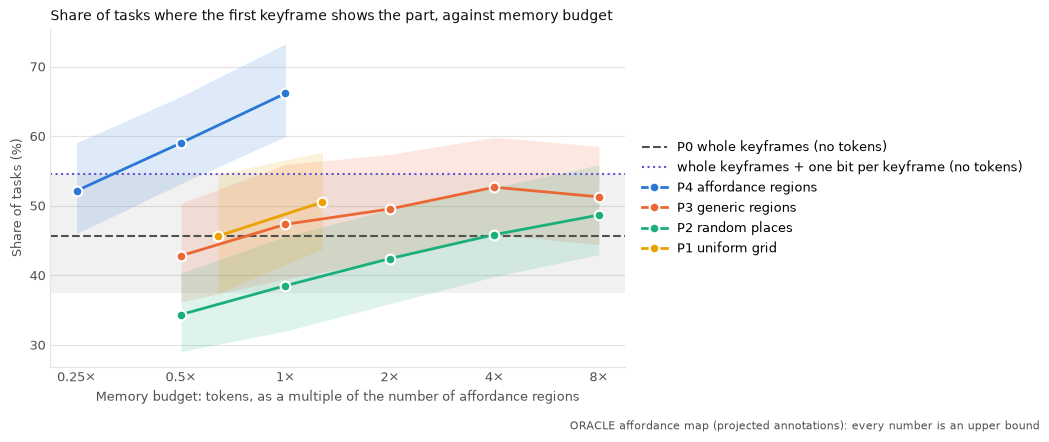

tokens  rate   low  high  scenes
policy                budget                                  
P4 affordance regions 0.25      15.0  52.2  46.0  59.1      30
                      0.50      31.0  59.0  53.2  65.7      30
                      1.00      62.0  66.2  60.0  73.3      30
P3 generic regions    0.50      31.0  42.8  36.2  50.3      30
                      1.00      62.0  47.3  39.5  55.9      30
                      2.00     123.0  49.5  42.3  57.4      30
                      4.00     247.0  52.7  45.9  59.8      30
                      8.00     493.0  51.3  44.4  58.5      30
P2 random places      0.50      31.0  34.4  29.1  40.3      30
                      1.00      62.0  38.5  32.0  45.6      30
                      2.00     123.0  42.4  35.9  49.5      30
                      4.00     247.0  45.8  39.8  52.6      30
                      8.00     493.0  48.7  43.0  55.9      30
P1 uniform grid 1x1   0.64      40.0  45.6  37.4  54.5      30
P1 uniform grid 2x1   1.28      80.0  50.5  43.8  57.7      30
P1 uniform grid 2x2   2.35     160.0  51.8  45.2  59.0      29
P1 uniform grid 3x2   3.50     240.0  51.8  45.4  59.4      28
P1 uniform grid 3x3   5.18     360.0  55.4  49.0  62.5      26
P1 uniform grid 4x3   6.72     480.0  51.6  43.2  61.8      22
P1 uniform grid 4x4   7.86     640.0  54.2  46.1  64.2      18
P1 uniform grid 6x4   10.61    960.0  54.1  45.5  65.1      10

In [6]:
R.budget_figure(results, "hit1", "the first keyframe shows the part", bit=diagnostics["first_keyframe_right"][R.BIT])
plt.show()
curves = pd.DataFrame([point for name in (A.P4, A.P3, A.P2, A.P1) for point in summary["curves"][name]])
curves[["rate", "low", "high"]] = (100 * curves[["rate", "low", "high"]]).round(1)
display(curves.round({"budget": 2, "tokens": 0}).set_index(["policy", "budget"]))

**多给预算以后再比一次。** 这一项不属于预先写定的判定规则，是为了排除一个可能的偏差而加的检查。

预算为 1 倍时，P2、P3 的 token 是散开取的，会有一些关键帧一个 token 也没有（第 3 节的输出里有那个场景的数目）；而打分公式给没有 token 的关键帧一个固定的低分。对 P4，"这一帧没有可操作的部件"是有用的信息；对 P2、P3，哪一帧没有 token 只是运气。预算到 4 至 8 倍时，P2、P3 这种靠运气的空关键帧基本没有了（第 11 节给出数目）。但 P4 从"哪些关键帧里有可操作的部件"得到的信息仍然在，所以下表同样不能读成 token 的效率。

下表是 **P4 在 1 倍预算下的结果，减去其他写法在更大预算下的结果**（同一批任务成对比较，单位是百分点）。

In [7]:
display(R.rates_table(summary["affordance_at_one_against_more"]))

,value,"95% interval, low","95% interval, high"
P4 at 1x minus P3 at 2x,16.6,11.2,22.8
P4 at 1x minus P3 at 4x,13.5,8.1,19.8
P4 at 1x minus P3 at 8x,14.9,9.2,21.3
P4 at 1x minus P2 at 2x,23.7,20.1,27.4
P4 at 1x minus P2 at 4x,20.3,17.1,24.2
P4 at 1x minus P2 at 8x,17.5,13.4,21.9
"P4 at 1x minus P1 uniform grid 1x1 (about 0.6x, 30 scenes)",20.5,14.4,26.9
"P4 at 1x minus P1 uniform grid 2x1 (about 1.3x, 30 scenes)",15.6,10.0,21.9
"P4 at 1x minus P1 uniform grid 2x2 (about 2.4x, 29 scenes)",14.1,8.6,19.5
"P4 at 1x minus P1 uniform grid 3x2 (about 3.5x, 28 scenes)",13.7,7.8,19.2


**token 比只有整帧多带来什么？** 同样是规格之外的补充：各种写法减去 P0（成对比较，百分点）。最后两行是 P4 只留四分之一和一半的 token，可以看作 affordance map 漏掉一部分部件时的情形。再下面是 P2、P3 在 1 倍预算下各个随机种子的最低和最高结果。

In [8]:
display(R.rates_table(summary["others_against_whole"]))
spread = pd.DataFrame(summary["seed_spread"]).T
spread[["lowest", "highest"]] = (100 * spread[["lowest", "highest"]]).round(1)
display(spread)

,value,"95% interval, low","95% interval, high"
P3 at 1x minus P0,1.7,-3.5,7.5
P3 at 4x minus P0,7.0,2.6,11.7
P3 at 8x minus P0,5.6,0.2,11.7
P2 at 1x minus P0,-7.1,-11.7,-2.3
P2 at 8x minus P0,3.0,-1.5,7.8
P1 uniform grid 2x1 minus P0,4.9,0.8,8.9
P4 at 0.25x minus P0,6.5,0.4,13.6
P4 at 0.5x minus P0,13.4,6.9,20.5


,seeds,lowest,highest
P2,5.0,36.7,41.5
P3,5.0,45.9,49.0


## 6. 逐个场景看

总体的差可能来自少数几个场景。下面把每个场景里"P4 减去另一种写法"的差从大到小排开。

**怎么看图：** 每根柱是一个场景。柱子朝上（P4 的颜色）表示这个场景里 P4 更好，朝下（另一种写法的颜色）表示另一种写法更好。每个场景的任务数从 3 条到 27 条不等，任务少的场景柱子会很长（P4 − P0 一格里最朝下的那一根，是只有 3 条任务的场景）。

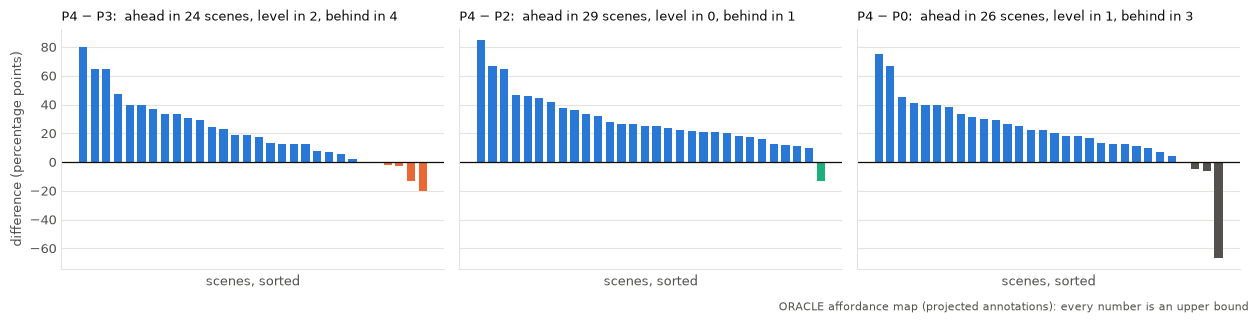

In [9]:
R.per_scene_figure(results)
plt.show()

## 7. 得分最高的 token 是否落在目标部件上

上面的指标只看关键帧对不对。这里再看一步：对查询得分最高的那个 token，它的区域是否盖住了任务所指的部件。同时给出区域的面积，避免"框大所以容易中"。

In [10]:
display(R.token_table(results))

,best token is on the target part (%),95% interval,tokens per scene,median region area (% of the image)
P4 affordance regions,30.0,24.7 to 36.2,61.7,0.06
P3 generic regions,5.4,3.4 to 8.0,61.7,0.06
P2 random places,1.0,0.5 to 1.5,61.7,0.06


## 8. 端到端：把前 3 个关键帧交给视觉语言模型

检索之后，把得分最高的 3 个关键帧连同 token 的编号框交给视觉语言模型，让它选一个框。选中的框盖住任务所指的部件，算对。只对 P4 和 P3 做。

**怎么看图：** 与第 4 节的画法相同。注意这一步的绝对数字不高：模型看的是整幅关键帧，小部件在图里很小（[pipeline.ipynb](pipeline.ipynb) 环节 10 里记着这个缺口）。

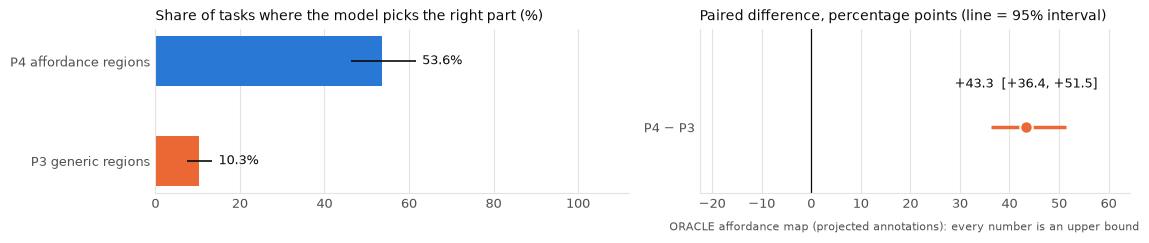

,value,"95% interval, low","95% interval, high"
P4 affordance regions,53.6,46.2,61.6
P3 generic regions,10.3,7.5,13.4
P4 minus P3,43.3,36.4,51.5


numbered boxes shown to the model per task, mean: {'P4 affordance regions': 10.6, 'P3 generic regions': 8.6}


In [11]:
R.reading_figure(summary)
plt.show()
display(R.rates_table({name: row for name, row in summary["reading"].items()}))
shown_marks = {name: float(np.mean([np.mean(result["reading"][name]["marks_shown"]) for result in results]))
               for name in R.READING_NAMES.values() if name in summary["reading"]}
print("numbered boxes shown to the model per task, mean:", {name: round(value, 1) for name, value in shown_marks.items()})

### 几个具体的任务

还是第 3 节那个场景。在 CPU 上重新算一遍它的检索（与 GPU 上的结果逐条核对），然后按固定的规则取任务：先取"P4 对而 P3 错"的，再取"P4 对而 P2 错"的，再取"P4 错"的；没有就跳过。

**怎么看图：** 每一行是一条任务，每一列是一种写法排在第 1 位的关键帧。彩色框是这个关键帧里得分最高的 token；绿色圆圈是任务所指的部件（只有关键帧对的时候才有）。画面的边框绿色表示关键帧对，红色表示错。

same outcome as the GPU run: {'P0 whole keyframes': '14 of 14', 'P2 random places': '14 of 14', 'P3 generic regions': '14 of 14', 'P4 affordance regions': '14 of 14'}
ranking the keyframes for one query: 0.1 ms on the CPU (40 keyframes, 51 tokens); turning the query into a vector: 17 ms on the CPU


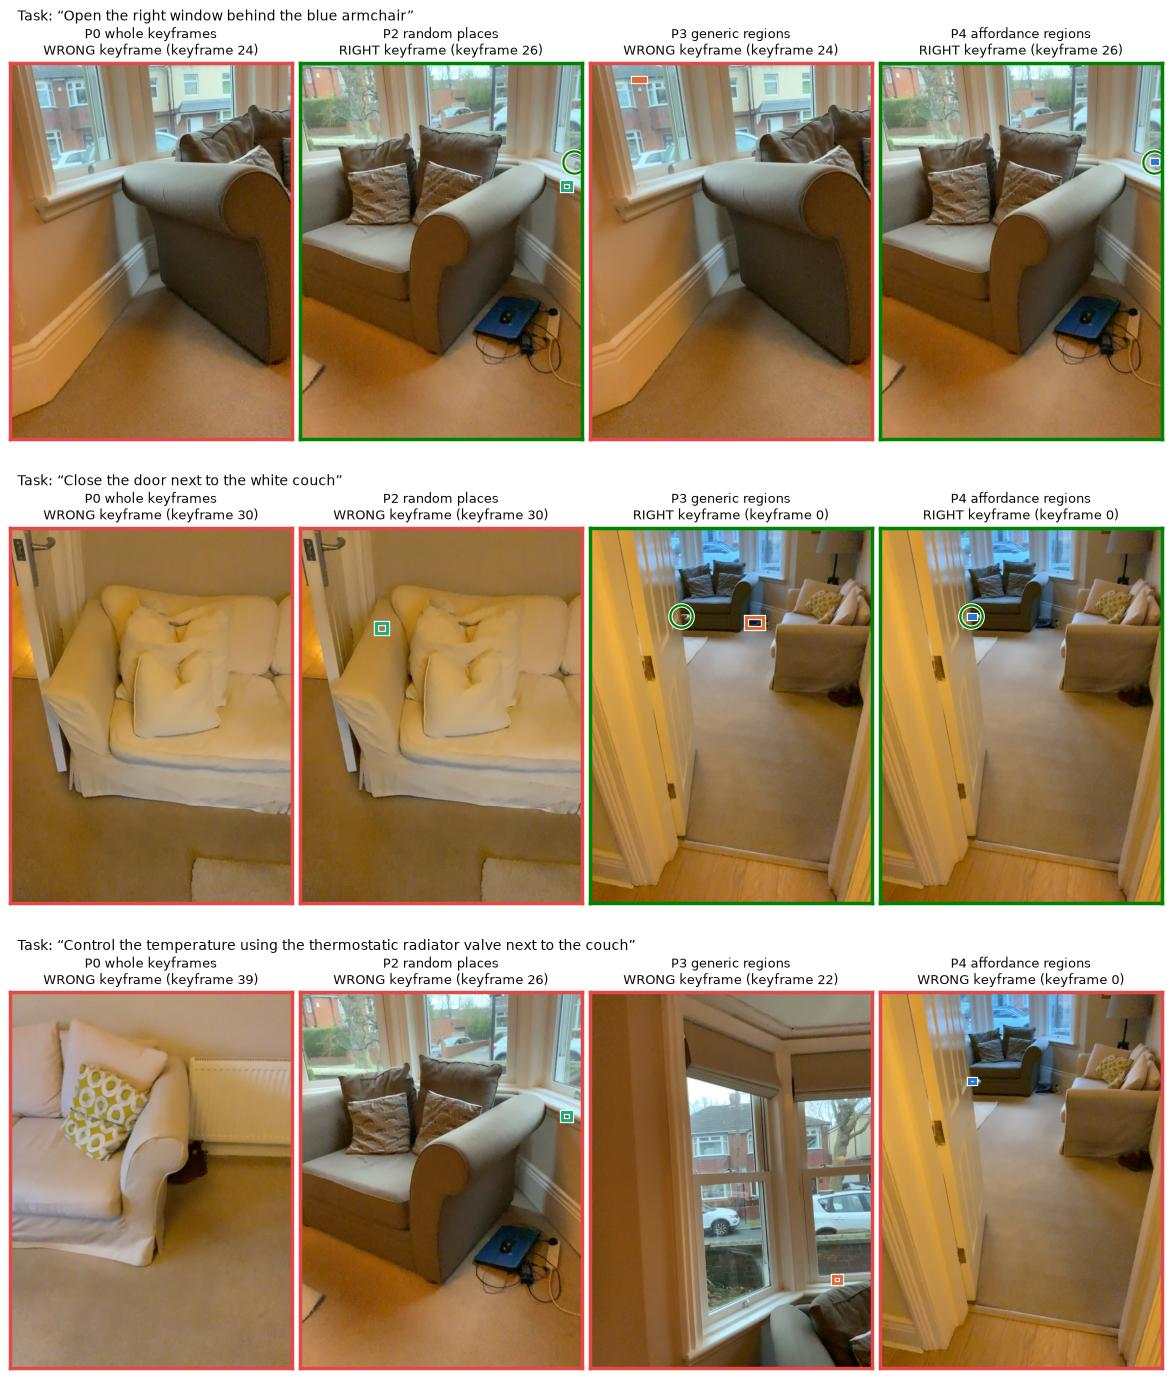

In [12]:
encoder = ImageTextEncoder()
keyframe_vectors = encoder.images([frame.rgb for frame in frames])
vectors = {name: encoder.images(R.crops_of(frames, sets[name])) for name in (A.P2, A.P3, A.P4)}
tasks = [task for task in H.tasks_of(scene, labels) if task.keyframes]
start = time.time()
queries = encoder.texts([task.text for task in tasks])
text_ms = 1000 * (time.time() - start) / len(tasks)
no_tokens = np.zeros((0, keyframe_vectors.shape[1]))
start = time.time()
picks = [{A.P0: R.first_pick(query, keyframe_vectors, [], no_tokens, task.keyframes),
          **{name: R.first_pick(query, keyframe_vectors, sets[name], vectors[name], task.keyframes) for name in (A.P2, A.P3, A.P4)}}
         for query, task in zip(queries, tasks)]
search_ms = 1000 * (time.time() - start) / (4 * len(tasks))

agreement = {}
for name in (A.P0, A.P2, A.P3, A.P4):  # the same tasks, the same token places: the CPU should repeat the GPU run
    stored = next(run for run in example["search"] if run["policy"].startswith(name) and run["seed"] == 0
                  and (name == A.P0 or run["budget"] == 1.0))["hit1"]
    agreement[R.POLICY_NAMES[name]] = f"{sum(int(pick[name].right) == hit for pick, hit in zip(picks, stored))} of {len(tasks)}"
print("same outcome as the GPU run:", agreement)
print(f"ranking the keyframes for one query: {search_ms:.1f} ms on the CPU ({len(frames)} keyframes, {len(sets[A.P4])} tokens); "
      f"turning the query into a vector: {text_ms:.0f} ms on the CPU")

chosen = R.choose_examples(picks, n=3)
set_matplotlib_formats("jpeg")
R.picks_figure(frames, [tasks[i].text for i in chosen], [picks[i] for i in chosen],
               [R.target_pixels(labels, tasks[i].parts) for i in chosen])
plt.show()

## 9. 几何和代价：要不要先重建

L2 记忆不存接触点，查询时从证据关键帧现算。对照做法是先把 40 个关键帧的深度融合成一份点云，再从点云上读。两种读法用同样的关键帧、同样的深度和位姿、同样的 ORACLE 标注；为了只比较读法，这张表按真实的部件编号统计。

**怎么看表：** "误差"是读出的接触点到扫描里这个部件的距离。"3 厘米以内"是能直接去碰的精度。第二行是完整的 L2 读法（部件由记忆自己跨帧关联，没有用部件编号），放在这里作参考。这里的"融合"是把同样的 40 张单目深度图投到一起、按体素去重，没有做多视角一致性检查，也不是 TSDF；所以它只说明"简单融合同样的深度图"并不更准。第二张表是在两种读法都读得出的部件上成对比较。最后一张表里的写入时间不含选关键帧、估计单目深度和预测 affordance map 的时间。

In [13]:
display(R.geometry_table(results, summary))
paired = pd.DataFrame(summary["geometry_paired"]).T
paired["single_frame_closer"] = (100 * paired["single_frame_closer"]).round(1)
display(paired.round(2).rename(columns={"parts": "parts read both ways", "median_difference_cm": "fused minus single keyframe, median (cm)",
                                        "low": "95% interval, low", "high": "95% interval, high",
                                        "single_frame_closer": "single keyframe closer (% of parts)",
                                        "read_ms_per_part": "read time per part (ms)"}))
display(R.cost_table(summary))

,parts,contact read,median error (cm),within 3 cm (% of read),within 3 cm (% of all parts),extra storage per scene (MB),build time per scene (s),read time per part (ms)
"one keyframe, read now (true part ids)",481.0,481.0,4.1,38.5,38.5,0.0,0.0,NaN
"one keyframe, read now (parts linked by the memory)",760.0,760.0,5.5,31.6,31.6,0.0,0.0,17.6
"fused cloud, 1 cm voxels",481.0,466.0,5.4,31.8,30.8,22.5,2.4,130.7
"fused cloud, 2 cm voxels",481.0,441.0,6.0,28.8,26.4,6.5,1.2,57.3
"fused cloud, 5 cm voxels",481.0,290.0,7.7,20.7,12.5,1.0,1.0,36.0


,parts read both ways,"fused minus single keyframe, median (cm)","95% interval, low","95% interval, high",single keyframe closer (% of parts),read time per part (ms)
fused 0.01 m,466.0,0.26,0.12,0.35,58.6,130.67
fused 0.02 m,441.0,0.36,0.21,0.69,60.3,57.33
fused 0.05 m,290.0,0.91,0.47,1.38,67.2,35.96


,value
what,
keyframe images (MB per scene),14.20
depth maps (MB per scene),13.20
affordance maps (MB per scene),0.09
token features (MB per scene),0.14
tokens per scene,61.70
"writing the memory (s per scene, affordance map given)",24.30
"model reading, P4 affordance regions (s per query, median)",1.30
"model reading, P3 generic regions (s per query, median)",1.30


## 10. 关口 G1 的判定

判定标准原文（讨论稿第 21.6 节，跑实验之前写定）。预算为 1 倍时：

- **通过：** P4 的"第一个关键帧对"高于 P3，差值的 95% 置信区间不包含 0；并且端到端选对的比例 P4 不低于 P3。
- **部分通过：** P4 只高于 P2（随机位置），与 P3 没有显著差别。
- **不通过：** P4 不高于 P2。

In [14]:
first, reading = summary["first_keyframe_right"], summary["reading"]
verdict = pd.DataFrame({
    "P4 minus P3, first keyframe right (points)": first["P4 minus P3"], "P4 minus P2, first keyframe right (points)": first["P4 minus P2"],
    "model picks the right part, P4 (%)": reading[R.READING_NAMES[A.P4]], "model picks the right part, P3 (%)": reading[R.READING_NAMES[A.P3]],
}).T[["rate", "low", "high"]]
display((100 * verdict).round(1).rename(columns={"rate": "value", "low": "95% interval, low", "high": "95% interval, high"}))
print("rule of section 21.6, category:", summary["rule_21_6_category"], "| whether gate G1 is passed is the project lead's decision")

,value,"95% interval, low","95% interval, high"
"P4 minus P3, first keyframe right (points)",18.8,12.9,24.9
"P4 minus P2, first keyframe right (points)",27.6,23.5,32.0
"model picks the right part, P4 (%)",53.6,46.2,61.6
"model picks the right part, P3 (%)",10.3,7.5,13.4


rule of section 21.6, category: passed | whether gate G1 is passed is the project lead's decision


## 11. 审稿后加的检查：增益从哪里来

这份结果交给项目负责人之前，由一位独立的审稿人审了一遍。他指出一个第 4、5 节没有分开的问题：

- 打分公式里，一个关键帧如果没有任何 token，token 这一项记为 −3 个标准差。
- 对 P4，"没有 token"等于"这个关键帧里没有标注的可操作部件"，而任务所指的部件一定在有 token 的关键帧里。所以 P4 同时得到了两样东西：**token 的内容**，和**"哪些关键帧值得看"这个帧级信息**。
- 对 P2、P3，哪个关键帧没有 token 只是运气。

下面的检查把这两样分开。计划和每种结果怎么读，是在算之前写定并提交的（讨论稿第 23.2 节）。P2、P3 用 3 个随机种子，只用 CPU；用 CPU 重算的结果与 GPU 上的原结果逐条相同。

| 对照组 | 它知道什么 |
| --- | --- |
| 整帧 + 每帧一个比特 | 哪些关键帧里有 affordance 区域；不用任何 token 的内容 |
| 放进 P4 关键帧的 P2、P3（图里带斜线） | 与 P4 相同的关键帧、每帧个数也相同；帧内的位置是随机的，或者是通用区域 |

**怎么看图：** 左边是五个对照组"第一个关键帧对"的比例。右边是相邻两步之间的差：第 1 行是帧级信息单独值多少，第 2 行是 P4 的 token 在帧级信息之上再加多少，第 3、4 行是关键帧相同时"帧内取在哪里"值多少。

CPU repeats the GPU run (task outcomes): {'P0': '390 of 390', 'P4': '390 of 390', 'P2': '1170 of 1170', 'P3': '1170 of 1170', 'P1': '390 of 390'}


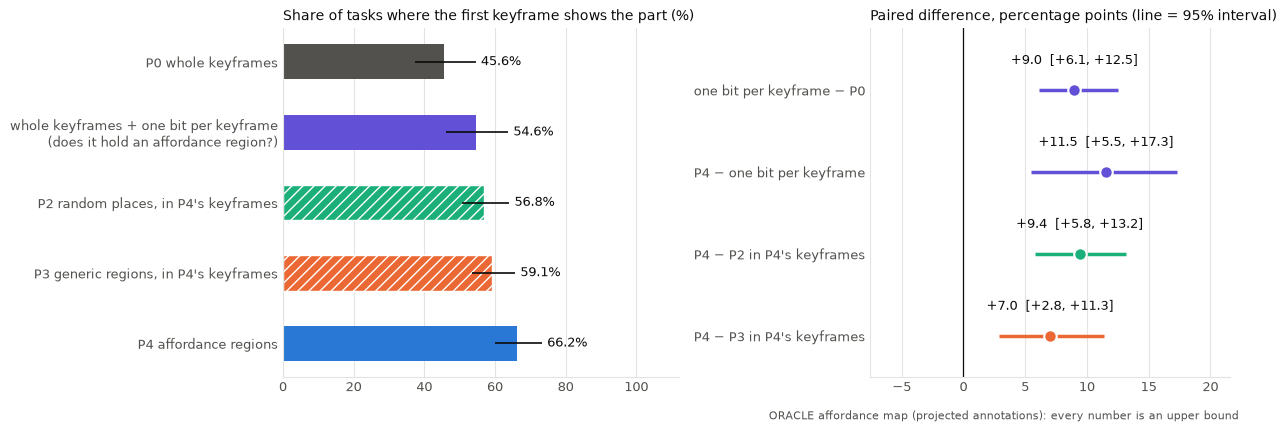

,value,"95% interval, low","95% interval, high"
P0 whole keyframes,45.6,37.4,54.5
P4 affordance regions,66.2,60.0,73.3
P3 generic regions,47.4,39.9,55.7
P2 random places,39.4,32.0,47.4
P1 uniform grid 2x1,50.5,43.8,57.7
whole keyframes + which keyframes hold an affordance region,54.6,46.1,63.7
"P4, no penalty for keyframes without a token",63.1,56.9,70.2
"P3, no penalty for keyframes without a token",48.2,41.0,56.2
"P2, no penalty for keyframes without a token",39.9,32.3,47.9
P3 in the keyframes of P4,59.1,53.4,65.7


In [15]:
print("CPU repeats the GPU run (task outcomes):", diagnostics["repeats_the_run"])
set_matplotlib_formats("png")
R.attribution_figure(diagnostics)
plt.show()
display(R.rates_table({**diagnostics["first_keyframe_right"], **diagnostics["differences"]}))

**结论会不会随打分公式里的两个常数改变？** 下表是每个对照组在 12 组常数下的结果（百分比）：token 一项的权重取 0.25、0.5、1、2；没有 token 的关键帧记 0、−1、−3。原实验用的是"权重 1、−3"。第二张表是 P4（原来的常数）减去每个基线在它自己最好的一组常数下的结果；基线的"最好"是在这 30 个场景上挑的，对基线偏乐观。第三张表是两种写法用同一组常数时，P4 减"放进 P4 关键帧的 P3"的差：token 的权重取 1 或 2 时区间都不含 0，取 0.5 或 0.25 时差变小，多数区间含 0。

最后几行输出：随机选一个关键帧的命中率；端到端一步里给模型看的框有没有一个在目标部件上；各种写法没有 token 的关键帧数；区域面积的中位数（放进 P4 关键帧的 P2 与 P4 完全相同，P3 是 P4 的 1.7 倍左右）；以及 P4 只留四分之一、一半的 token 时，有和没有扣分项的结果。

In [16]:
display(R.sweep_table(diagnostics))
print("best setting of each arm:", diagnostics["best_setting"])
display(R.rates_table(diagnostics["at_best_settings"]))
display(R.rates_table({setting: row["P4 minus P3 same keyframes"] for setting, row in diagnostics["same_setting"].items()}))
print("median region area in pixels:", diagnostics["median_region_area_px"],
      "| P3 in P4's keyframes against P4, median over scenes:", round(diagnostics["area_ratio_same_keyframes_to_p4"], 2))
print("P4 with a part of its tokens, minus P0 (points):",
      {name: f"{100 * row['minus P0']['rate']:+.1f} ({100 * row['minus P0']['low']:+.1f} to {100 * row['minus P0']['high']:+.1f})"
       for name, row in diagnostics["misses"].items()})
print("chance that a random keyframe is right:", {name: f"{100 * value:.1f}%" for name, value in diagnostics["chance"].items()})
print("tasks where a box shown to the model lies on the target part:",
      {name: f"{100 * row['rate']:.1f}% ({100 * row['low']:.1f} to {100 * row['high']:.1f})"
       for name, row in diagnostics["a_shown_box_is_on_the_target"].items()})
print("keyframes without any token, of 40 (mean over scenes):",
      {name: round(value, 1) for name, value in diagnostics["keyframes_without_a_token_of_40"].items()})

,P4 affordance regions,P3 in P4's keyframes,P2 in P4's keyframes,P3 generic regions,P2 random places,P1 uniform grid 2x1,one bit per keyframe
"weight 0.25, empty 0",54.4,53.1,51.1,51.0,47.0,48.2,45.6
"weight 0.25, empty -1",57.4,55.0,53.7,50.4,46.5,48.2,49.5
"weight 0.25, empty -3",60.0,57.9,56.8,50.0,46.3,48.2,53.1
"weight 0.5, empty 0",57.9,55.4,53.8,50.1,45.1,47.7,45.6
"weight 0.5, empty -1",60.5,57.6,56.8,49.7,44.4,47.7,51.5
"weight 0.5, empty -3",63.8,59.0,58.9,49.0,42.8,47.7,54.4
"weight 1, empty 0",63.1,57.5,55.0,48.2,39.9,50.5,45.6
"weight 1, empty -1",65.9,59.0,56.7,47.8,39.4,50.5,53.3
"weight 1, empty -3",66.2,59.1,56.8,47.4,39.4,50.5,54.6
"weight 2, empty 0",63.8,57.4,52.6,44.9,35.0,48.7,45.6


best setting of each arm: {'P4': 'weight 1, empty -3', 'P1': 'weight 1, empty 0', 'P2': 'weight 0.25, empty 0', 'P3': 'weight 0.25, empty 0', 'shortlist': 'weight 1, empty -3', 'P3 same keyframes': 'weight 1, empty -3', 'P2 same keyframes': 'weight 0.5, empty -3'}


,value,"95% interval, low","95% interval, high"
P4 (default) minus P1 at its best setting,15.6,10.0,21.9
P4 (default) minus P2 at its best setting,19.1,13.7,25.3
P4 (default) minus P3 at its best setting,15.1,9.9,20.4
P4 (default) minus shortlist at its best setting,11.5,5.5,17.3
P4 (default) minus P3 same keyframes at its best setting,7.0,2.8,11.3
P4 (default) minus P2 same keyframes at its best setting,7.3,3.8,10.9


,value,"95% interval, low","95% interval, high"
"weight 0.25, empty 0",1.3,-2.2,5.2
"weight 0.25, empty -1",2.5,-0.2,5.5
"weight 0.25, empty -3",2.1,-0.8,5.6
"weight 0.5, empty 0",2.6,-1.6,6.9
"weight 0.5, empty -1",2.9,-1.3,7.4
"weight 0.5, empty -3",4.9,0.5,10.0
"weight 1, empty 0",5.6,1.4,10.0
"weight 1, empty -1",6.9,2.8,11.4
"weight 1, empty -3",7.0,2.8,11.3
"weight 2, empty 0",6.4,0.9,11.4


median region area in pixels: {'P4': 429.0, 'P3 same keyframes': 784.25, 'P2 same keyframes': 429.0, 'P3': 425.25} | P3 in P4's keyframes against P4, median over scenes: 1.74
P4 with a part of its tokens, minus P0 (points): {'P4 with 0.25 of its tokens, empty -3': '+6.5 (+0.4 to +13.6)', 'P4 with 0.25 of its tokens, empty 0': '+6.0 (+0.6 to +12.3)', 'P4 with 0.5 of its tokens, empty -3': '+13.4 (+6.9 to +20.5)', 'P4 with 0.5 of its tokens, empty 0': '+10.8 (+5.0 to +17.3)'}
chance that a random keyframe is right: {'a random keyframe': '9.2%', 'a random keyframe among those with an affordance region': '17.3%'}
tasks where a box shown to the model lies on the target part: {'P4 affordance regions': '83.6% (78.2 to 89.3)', 'P3 generic regions': '20.0% (13.8 to 27.9)'}
keyframes without any token, of 40 (mean over scenes): {'P2 at 1x': 10.1, 'P3 at 1x': 14.9, 'P2 at 2x': 3.9, 'P3 at 2x': 8.0, 'P2 at 4x': 1.1, 'P3 at 4x': 3.2, 'P2 at 8x': 0.2, 'P3 at 8x': 1.2, 'P4 at 1x': 19.1}


## 12. 怎么读这些结果

**按预先写定的规则，G1 的条件都满足：** P4 比 P3 高，差值的区间不含 0；端到端选对的比例 P4 不低于 P3；P4 也高于 P2。**关口是否通过，由项目负责人决定。**

**结果说明了什么**（都是 ORACLE 的上限）

1. **预算相同时，P4 把正确的关键帧排在第 1 位的比例最高。** P4 66.2%，P3 47.3%，P0 45.6%，P2 38.5%。P4 比 P3 高 18.8 个百分点（区间 12.9 到 24.9）。
2. **这个增益里有两样东西：帧级的信息，和 token 本身（第 11 节）。** 只用帧级信息（每个关键帧一个比特，不写任何 token），比只有整帧高 9.0 个百分点（区间 6.1 到 12.5）。只用 token（去掉对空关键帧的扣分），高 17.4 个百分点（区间 11.7 到 23.7）；这里面仍然包含"token 只出现在有可操作部件的关键帧里"这一点，因为同样去掉扣分，把通用区域放进 P4 的关键帧也有 57.5%（比只有整帧高 11.9 个百分点）。两样都用，高 20.5 个百分点。
3. **关键帧相同时，取在 affordance 区域上比取在别处高 7 到 9 个百分点；这个数依赖检索时给 token 的权重。** 对通用区域是 7.0 个百分点（区间 2.8 到 11.3），对随机位置是 9.4 个百分点（区间 5.8 到 13.2）。18.8 是整套写法对 P3 的差，7.0 是其中"帧内取在哪里"的那一部分。token 的权重取 1 或 2 时这个差是 5.6 到 7.0 个百分点，区间都不含 0；权重降到 0.5 或 0.25 时缩小到 1.3 到 4.9 个百分点，多数区间含 0。
4. **不按 affordance 写的方法，在试过的预算里都没有追上；但这主要说明帧级的功能信息很值钱，不能读成 token 的效率。** 在 30 个场景都跑了的设置里，P3 最高是 4 倍预算时的 52.7%，而"每帧一个比特"不写任何 token 就是 54.6%。P4 在 1 倍预算下比 P3 在 8 倍预算下高 14.9 个百分点（区间 9.2 到 21.3）。每个基线取 12 组常数里最好的一组，P4 仍领先 15 个百分点以上。
5. **不按 affordance 取的 token，在 1 倍预算下比只有整帧多不出什么；预算加大后能多出几个百分点。** 1 倍时，通用区域 +1.7（区间 −3.5 到 +7.5），随机位置 −7.1（区间 −11.7 到 −2.3）。通用区域到 4 倍时是 +7.0（区间 2.6 到 11.7）。
6. **端到端的差距主要来自候选。** 视觉语言模型选对部件的比例：P4 53.6%，P3 10.3%。给模型看的框里有一个在目标部件上的任务，P4 是 83.6%，P3 只有 20.0%。
7. **简单融合同样的深度图，没有让接触点更准。** 从单个关键帧现算，中位误差 4.1 厘米；融合成 1 厘米体素的点云再读，是 5.4 厘米。在两种读法都读得出的 466 个部件上成对比较，融合的误差中位数多 0.26 厘米（区间 0.12 到 0.35）。

**结果没有说明什么**

- **这是最有利于 affordance 的设定。** affordance map 是标注投影来的，而 SceneFun3D 的任务只问标注过的功能部件：任务所指的部件一定在有 affordance 区域的关键帧里。换成模型预测的 affordance map，会漏、会错，增益会缩小；缩小多少，要到阶段 2 才知道。
- **漏掉部件时，增益会很快变小。** P4 随机只留四分之一的 token，比只有整帧只高 6.5 个百分点（区间 0.4 到 13.6）；去掉对空关键帧的扣分再算，也差不多（6.0 个百分点）。
- **没有测"普通物体"的查询。** affordance token 对这类查询会不会变差，这次回答不了。
- **P3 只是通用区域的一种取法。** 这里用的是 SAM 的分割结果，按大小与 P4 匹配后取。其他取法（例如开放词表检测器给出的区域）没有比；把全部分割区域都写进记忆的上限也没有跑。
- **接触精度仍然不够。** 两种读法落在 3 厘米以内的都不到四成。
- **没有成立的一项：** 选相机转得慢的帧，关键帧处的转速中位数从每秒 21.0 度降到 8.1 度，但看得到的部件没有变多，反而略少（561 个部件里 481 个；均匀取帧是 501 个）。

**与规格（讨论稿第 21 节）不同的地方**

- 6 个场景里共有 7 个关键帧，数据集给的 LiDAR 置信度整张为 0，无法按规格用 LiDAR 校正单目深度的尺度。这些帧改用同一场景其余关键帧的尺度中位数（只用输入）。
- 1 个场景里有一个 affordance 区域大到填满了算法线用的窗口。这种情况改用区域自身的表面算法线。
- 这两处修正之后，30 个场景全部在修正后的代码上重跑了一遍；原先成功的 23 个场景，结果与第一次逐条相同。
- 端到端一步里，P3 只用了一个随机种子的 token（规格写的是 5 个种子；检索指标用了 5 个）。
- "token 在目标部件上"的判断，给区域框留了 8 个像素的余量。
- P3 "按大小匹配"取的是面积最接近的区域，不同种子取到的区域有重叠，不是相互独立的抽取。
- 第 5 节后面的表和第 11 节，是规格之外加的检查，不参与第 10 节的判定。
- 预算曲线里，一档网格的 token 数超过 P4 的 12 倍时不跑，所以 token 少的场景里没有细网格；图上只画了 30 个场景都有的两档，全部档位在表里（最后一列是场景数）。

完整的记录在[讨论稿](../../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md)第 22、23 节，审稿意见和处理在 `helm/REVIEW.md`。